# GRADIEND: learn your own feature

A feature is the difference between two classes of words that a language model can predict. To learn one, you turn it into data: sentences in which a word of one class is masked, plus a word of the other class as the alternative.
The steps below use one example, **British vs American spelling**. Replace the words and the text to learn your own feature.

1. **Define the two classes** and a proxy for each: words that express them (BE: *colour*, AE: *color*).
2. **Pick a base text** that contains these words (here Wikipedia, wikitext).
3. **Generate masked data** with `TextPredictionDataCreator`. Give each class its words as a `TextFilterConfig` (a word list per class, as in the [sentiment notebook](https://github.com/aieng-lab/gradiend/blob/main/gradiend/examples/demo/02_sentiment.ipynb)).
   If every word of one class has exactly one partner in the other, as here, list the pairs with `PairedTextFilterConfig`: the partner becomes the alternative.
4. **Hold out words** (`split_by_target`) to test that the feature carries over to words the model was not trained on.
5. **Train and check** the encoder on the held-out words.

```
pip install gradiend[recommended]
```

In [1]:
import sys

if "google.colab" in sys.modules:  # on Colab: install the package first
    !pip install -q "gradiend[recommended]"

In [2]:
import transformers

transformers.logging.set_verbosity_error()  # quiet model-loading messages

MODEL = "bert-base-cased"  # any masked language model, e.g. "distilbert-base-cased" or "roberta-base"

In [3]:
from gradiend import PairedTextFilterConfig, TextPredictionDataCreator, TextPreprocessConfig

pairs = [("colour", "color"), ("centre", "center"), ("favour", "favor"), ("honour", "honor"), ("neighbour", "neighbor"),
         ("flavour", "flavor"), ("defence", "defense"), ("organise", "organize"), ("realise", "realize"), ("analyse", "analyze")]

creator = TextPredictionDataCreator(
    base_data="Salesforce/wikitext", hf_config="wikitext-103-raw-v1", base_max_size=400_000,
    preprocess=TextPreprocessConfig(split_to_sentences=True, min_chars=40, max_chars=250),
    feature_targets=[PairedTextFilterConfig(pairs=pairs, ids=("BE", "AE"))],
)
# hold out whole pairs: 6 for training, 2 for validation, 2 for testing
data = creator.generate_training_data(max_size_per_class=1500, split_by_target=True, train_ratio=0.6, val_ratio=0.2, test_ratio=0.2)
data["BE"][["masked", "BE", "AE", "split"]].head()

2026-10-22 10:20:10 - WARNING - Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.


2026-10-22 10:20:28 - INFO -   BE: 1500/1500 matches (0.41% of sentences scanned)


2026-10-22 10:20:28 - INFO -   AE: 1500/1500 matches (0.64% of sentences scanned)


2026-10-22 10:20:28 - INFO - Overall: 3000/3000 (100.0%)


2026-10-22 10:20:28 - INFO - Training filter stats (instances per group): {'BE': 1500, 'AE': 1500}


2026-10-22 10:20:28 - INFO - Match rate per class (fraction of sentences scanned): {'BE': '0.41%', 'AE': '0.64%'}


,masked,BE,AE,split
0,Churchill in his capacity as Minister of Defen...,Defence,defense,train
1,Brown assumed that they extended from the beak...,centre,center,train
2,"( Based on this evidence , Chagford now has a ...",honour,honor,train
3,"In December 2014 , 24 World War II bombs weigh...",centre,center,train
4,They were subsequently authorised to wear the ...,colour,color,test


Every pair is in exactly one split, whatever its casing (*Colour* / *colour*):

In [4]:
data["BE"].groupby("split")["BE"].agg(lambda words: sorted(set(words.str.lower()))).to_frame("British words")

,British words
split,
test,"[colour, neighbour]"
train,"[analyse, centre, defence, flavour, honour, or..."
validation,"[favour, realise]"


## Train

The learning rate matters for a new feature, so let GRADIEND tune it (`learning_rate="tune"`): a few short probe runs, then the full training with the best value.
`source="factual"` makes the encoder read the gradient of the word that is in the text (by default it reads the alternative word), so every word is plotted at its own encoded value below.
Afterwards check that training converged. The log and the convergence plot show whether the encoder separates the two classes; if it does not, the [FAQ](https://aieng-lab.github.io/gradiend/faq/) lists what to try (learning rate, steps, pruning, more varied data).

2026-10-22 10:23:09 - INFO - lr_search: lr=1e-05 -> converged (final=0.9081808390322743 best=0.9081808390322743)


2026-10-22 10:25:50 - INFO - lr_search: lr=2e-05 -> converged (final=0.9413738598327788 best=0.9413738598327788)


2026-10-22 10:28:32 - INFO - lr_search: lr=5e-05 -> converged (final=0.9594425816079599 best=0.9594425816079599)


2026-10-22 10:29:45 - INFO - lr_search: lr=5e-06 -> slow (final=0.8343898891399554 best=0.8343898891399554)


2026-10-22 10:29:45 - INFO - Tuned learning rate: 2e-05


...

2026-10-22 10:31:20 - INFO - Wrote full training stats to runs/spelling/BE_AE/model/training.json


2026-10-22 10:31:20 - INFO - Saved convergence plot: runs/spelling/BE_AE/training_convergence.png


2026-10-22 10:31:20 - INFO - Saved training convergence plot: runs/spelling/BE_AE/training_convergence.png


tuned learning rate: 2e-05


2026-10-22 10:31:20 - INFO - Saved convergence plot: runs/spelling/BE_AE/training_convergence.png


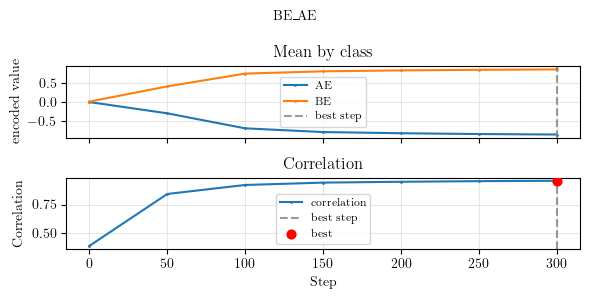

'runs/spelling/BE_AE/training_convergence.png'

In [5]:
from gradiend import PostPruneConfig, PrePruneConfig, TextPredictionTrainer, TrainingArguments

args = TrainingArguments(
    experiment_dir="runs/spelling", source="factual", learning_rate="tune", train_batch_size=8, max_steps=300, eval_steps=50,
    pre_prune_config=PrePruneConfig(n_samples=8, topk=0.1), post_prune_config=PostPruneConfig(topk=0.01),
)
trainer = TextPredictionTrainer(model=MODEL, run_id="BE_AE", data=data, target_classes=["BE", "AE"], args=args)
trainer.train()
print("tuned learning rate:", trainer.lr_search_result.best_lr)
trainer.plot_training_convergence()

## Check the feature on held-out words

The encoder should separate the two classes. The test pairs were never seen during training, so the correlation on them is the number to look at.
Hover over a point to read its masked sentence and the words involved.

In [6]:
enc = trainer.evaluate_encoder(split="all", max_size=None, return_df=True, plot=False)
trainer.plot_encoder_by_target(encoder_df=enc["encoder_df"], plot_style="strip", interactive=True);

2026-10-22 10:31:22 - INFO - Inferred decoder eval targets for BE_AE: {'BE': ['analyse', 'Defence', 'neighbour', 'defence', 'Realise', 'centre', 'flavour', 'Centre', 'colour', 'favour', 'organise', 'realise', 'Colour', 'Honour', 'Neighbour', 'Flavour', 'honour'], 'AE': ['analyze', 'center', 'Flavor', 'Realize', 'honor', 'color', 'Color', 'Center', 'favor', 'flavor', 'Defense', 'Honor', 'neighbor', 'realize', 'Neighbor', 'defense', 'organize']}


2026-10-22 10:31:22 - INFO - Computing encoder analysis for all variants


2026-10-22 10:31:22 - INFO - Encoding training data (max_size=None, source=factual, size=2976)


2026-10-22 10:32:23 - INFO - Encoding neutral training masked data (max_size=None, size=383)


2026-10-22 10:32:37 - INFO - Saved encoder analysis results to runs/spelling/BE_AE/encoded_values_split_train_validation_test.csv


In [7]:
test = trainer.evaluate_encoder(split="test", plot=False)
print("correlation on the held-out test pairs:", round(test["correlation"], 3))

2026-10-22 10:32:38 - INFO - Inferred decoder eval targets for BE_AE: {'BE': ['analyse', 'Defence', 'neighbour', 'defence', 'Realise', 'centre', 'flavour', 'Centre', 'colour', 'favour', 'organise', 'realise', 'Colour', 'Honour', 'Neighbour', 'Flavour', 'honour'], 'AE': ['analyze', 'center', 'Flavor', 'Realize', 'honor', 'color', 'Color', 'Center', 'favor', 'flavor', 'Defense', 'Honor', 'neighbor', 'realize', 'Neighbor', 'defense', 'organize']}


2026-10-22 10:32:38 - INFO - Computing encoder analysis for all variants


2026-10-22 10:32:38 - INFO - Encoding training data (max_size=None, source=factual, size=383)


2026-10-22 10:32:52 - INFO - Encoding neutral training masked data (max_size=None, size=383)


2026-10-22 10:33:06 - INFO - Saved encoder analysis results to runs/spelling/BE_AE/encoded_values_split_test.csv


correlation on the held-out test pairs: 0.988
